# SepsisShield — Person 1: Exploratory Data Analysis (EDA)

**Purpose:** Understand the actual PhysioNet Challenge 2019 dataset, audit its structure and data quality, visualize important clinical patterns, and write evidence-backed findings.

**Input:** `data/Dataset.csv` — the original user-provided merged CSV.

**Outputs:** EDA tables, charts and an evidence report in `outputs/01_eda/`.

> This notebook does not modify the original CSV, impute missing values, or delete statistical outliers. It investigates and documents them. `SepsisLabel` is the official early-warning target; it is already shifted six hours before the challenge-defined onset. Do not shift it again.

## 1. Import libraries and locate the project data

Run this notebook first. It uses pandas, NumPy and Matplotlib only.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the project root whether Jupyter starts in the project root or notebooks/.
_SEARCH_BASES = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
PROJECT_ROOT = None
for _base in _SEARCH_BASES:
    if (_base / "data" / "Dataset.csv").is_file():
        PROJECT_ROOT = _base
        break
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate project root. Expected data/Dataset.csv beneath the current folder. "
        f"Current directory: {Path.cwd().resolve()}"
    )

DATA_PATH = PROJECT_ROOT / "data" / "Dataset.csv"
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
REPORT_ROOT = PROJECT_ROOT / "reports"
OUTPUT_ROOT.mkdir(exist_ok=True)
REPORT_ROOT.mkdir(exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Original dataset:", DATA_PATH)
print("Dataset exists:", DATA_PATH.is_file())

EDA_DIR = OUTPUT_ROOT / "01_eda"
FIG_DIR = EDA_DIR / "figures"
EDA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

Project root: /Users/mohammedfaisalpasha/Downloads/SepsisShield_NIErnaya_Phase2
Original dataset: /Users/mohammedfaisalpasha/Downloads/SepsisShield_NIErnaya_Phase2/data/Dataset.csv
Dataset exists: True


## 2. Load and verify the original dataset

The original file is retained unchanged. We create an analysis view and remove `Unnamed: 0` only if it is an exact duplicate of `Hour`.

In [2]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Original shape:", df_raw.shape)
print("Memory usage (MB):", round(df_raw.memory_usage(deep=True).sum()/1024**2, 1))
display(df_raw.head())

required = {"Patient_ID", "Hour", "ICULOS", "SepsisLabel"}
missing_required = required - set(df_raw.columns)
if missing_required:
    raise ValueError(f"Required columns missing: {sorted(missing_required)}")

if "Unnamed: 0" in df_raw.columns and df_raw["Unnamed: 0"].equals(df_raw["Hour"]):
    df = df_raw.drop(columns=["Unnamed: 0"]).copy()
    print("Dropped redundant Unnamed: 0 from analysis copy (exact duplicate of Hour).")
else:
    df = df_raw.copy()
    print("No exact duplicate index column detected; retained original columns.")

print("Analysis shape:", df.shape)
print("Unique patients:", df["Patient_ID"].nunique())

Original shape: (1552210, 44)
Memory usage (MB): 521.1


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,...,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,1,65.0,100.0,NaN,NaN,72.0,NaN,16.5,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,2,78.0,100.0,NaN,NaN,42.5,NaN,NaN,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,3,73.0,100.0,NaN,NaN,NaN,NaN,17.0,NaN,...,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,4,70.0,100.0,NaN,129.0,74.0,69.0,14.0,NaN,...,NaN,330.0,68.54,0,NaN,NaN,-0.02,5,0,17072


Dropped redundant Unnamed: 0 from analysis copy (exact duplicate of Hour).
Analysis shape: (1552210, 43)
Unique patients: 40336


## 3. Dataset schema and variable groups

The source contains 8 vital-sign variables, 26 laboratory variables, 6 demographic/ICU context variables and the target label. This merged file additionally contains `Hour` and `Patient_ID` (and an export index column that may be redundant).

In [3]:
variable_groups = {
    "Vital signs": ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"],
    "Laboratory measurements": ["BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST", "BUN", "Alkalinephos", "Calcium", "Chloride", "Creatinine", "Bilirubin_direct", "Glucose", "Lactate", "Magnesium", "Phosphate", "Potassium", "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT", "WBC", "Fibrinogen", "Platelets"],
    "Demographic / ICU context": ["Age", "Gender", "Unit1", "Unit2", "HospAdmTime", "ICULOS"],
    "Project / target fields": ["Hour", "Patient_ID", "SepsisLabel"]
}
for group, cols in variable_groups.items():
    present = [c for c in cols if c in df.columns]
    print(f"{group}: {len(present)} columns")
    print(present)

schema = pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values,
                       "non_missing": df.notna().sum().values,
                       "missing": df.isna().sum().values,
                       "missing_pct": (df.isna().mean()*100).values})
display(schema)
schema.to_csv(EDA_DIR / "schema_and_missingness.csv", index=False)

Vital signs: 8 columns
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2']
Laboratory measurements: 26 columns
['BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets']
Demographic / ICU context: 6 columns
['Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS']
Project / target fields: 3 columns
['Hour', 'Patient_ID', 'SepsisLabel']


,column,dtype,non_missing,missing,missing_pct
0,Hour,int64,1552210,0,0.000000
1,HR,float64,1398811,153399,9.882619
2,O2Sat,float64,1349474,202736,13.061119
3,Temp,float64,525226,1026984,66.162697
4,SBP,float64,1325945,226265,14.576958
5,MAP,float64,1358940,193270,12.451279
6,DBP,float64,1065656,486554,31.345887
7,Resp,float64,1313875,238335,15.354559
8,EtCO2,float64,57636,1494574,96.286843
9,BaseExcess,float64,84145,1468065,94.579020


## 4. Structural integrity checks

Check duplicate rows, duplicate patient-hour pairs, label validity, patient counts and within-patient time ordering. Do not silently repair ambiguous duplicate patient-hour records.

In [4]:
exact_duplicates = int(df.duplicated().sum())
duplicate_patient_hours = int(df.duplicated(["Patient_ID", "Hour"]).sum())
invalid_labels = sorted(set(df["SepsisLabel"].dropna().unique()) - {0, 1})

ordered = df.sort_values(["Patient_ID", "Hour"], kind="mergesort")
hour_gap = ordered.groupby("Patient_ID", sort=False)["Hour"].diff()
nonconsecutive_gaps = int((hour_gap.notna() & hour_gap.ne(1)).sum())

patient_lengths = ordered.groupby("Patient_ID").size().rename("observations")
patient_outcome = ordered.groupby("Patient_ID")["SepsisLabel"].max().rename("any_positive_label")
positive_patients = int(patient_outcome.sum())

integrity = pd.Series({
    "rows": len(df), "columns_after_redundant_index_check": df.shape[1],
    "unique_patients": df["Patient_ID"].nunique(),
    "exact_duplicate_rows": exact_duplicates,
    "duplicate_patient_hour_pairs": duplicate_patient_hours,
    "nonconsecutive_hour_gaps": nonconsecutive_gaps,
    "invalid_label_values": len(invalid_labels),
    "positive_hourly_labels": int(df["SepsisLabel"].sum()),
    "positive_hourly_label_pct": float(df["SepsisLabel"].mean()*100),
    "patients_with_positive_label": positive_patients,
    "positive_patient_pct": float(positive_patients/df["Patient_ID"].nunique()*100),
    "median_observations_per_patient": float(patient_lengths.median()),
    "mean_observations_per_patient": float(patient_lengths.mean()),
    "min_observations_per_patient": int(patient_lengths.min()),
    "max_observations_per_patient": int(patient_lengths.max())
})
display(integrity.to_frame("value"))
integrity.to_csv(EDA_DIR / "dataset_integrity_summary.csv")

if invalid_labels:
    print("WARNING: unexpected labels:", invalid_labels)
if duplicate_patient_hours:
    print("WARNING: duplicate patient-hour keys require investigation before temporal processing.")
if nonconsecutive_gaps:
    print("WARNING: non-consecutive patient Hour gaps found; temporal windows must account for them.")

,value
rows,1.552210e+06
columns_after_redundant_index_check,4.300000e+01
unique_patients,4.033600e+04
exact_duplicate_rows,0.000000e+00
duplicate_patient_hour_pairs,0.000000e+00
nonconsecutive_hour_gaps,0.000000e+00
invalid_label_values,0.000000e+00
positive_hourly_labels,2.791600e+04
positive_hourly_label_pct,1.798468e+00
patients_with_positive_label,2.932000e+03


## 5. Class balance — hourly rows versus patients

These are different denominators. Report both. A small positive hourly-label percentage does not mean the same thing as the percentage of patients who ever receive a positive label.

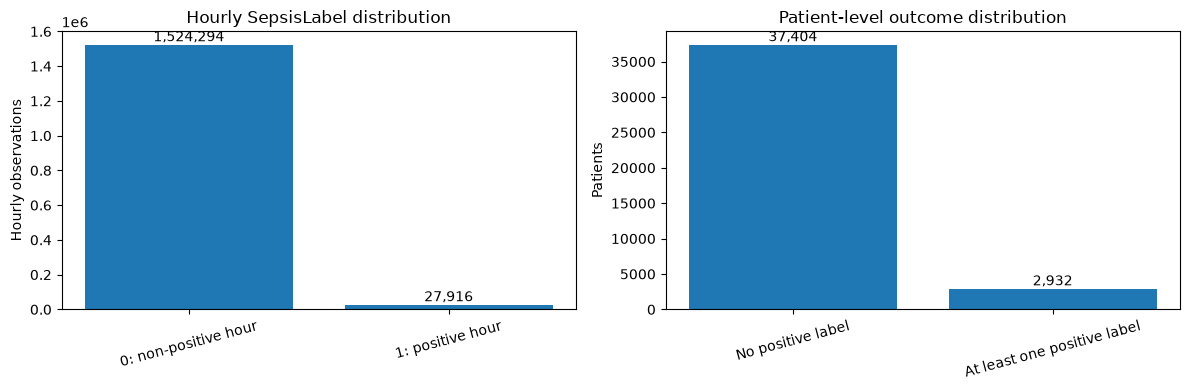

Positive hourly-label rate: 1.798 %
Patients with any positive label: 7.269 %


In [5]:
row_counts = df["SepsisLabel"].value_counts().reindex([0,1], fill_value=0)
patient_counts = patient_outcome.value_counts().reindex([0,1], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["0: non-positive hour", "1: positive hour"], row_counts.values)
axes[0].set_title("Hourly SepsisLabel distribution")
axes[0].set_ylabel("Hourly observations")
axes[0].tick_params(axis="x", rotation=15)
for i,v in enumerate(row_counts.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[1].bar(["No positive label", "At least one positive label"], patient_counts.values)
axes[1].set_title("Patient-level outcome distribution")
axes[1].set_ylabel("Patients")
axes[1].tick_params(axis="x", rotation=15)
for i,v in enumerate(patient_counts.values): axes[1].text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_label_balance_rows_vs_patients.png", dpi=160, bbox_inches="tight")
plt.show()

print("Positive hourly-label rate:", round(df["SepsisLabel"].mean()*100, 3), "%")
print("Patients with any positive label:", round(patient_outcome.mean()*100, 3), "%")

## 6. Missing-value investigation

Missing observations are common in ICU data because not every measurement is recorded every hour. We report missingness; we do not replace missing values in this notebook.

,missing_count,missing_pct
Bilirubin_direct,1549220,99.807371
Fibrinogen,1541968,99.340167
TroponinI,1537429,99.047745
Bilirubin_total,1529069,98.509158
Alkalinephos,1527269,98.393194
AST,1527027,98.377604
Lactate,1510764,97.329872
PTT,1506511,97.055875
SaO2,1498649,96.549372
EtCO2,1494574,96.286843


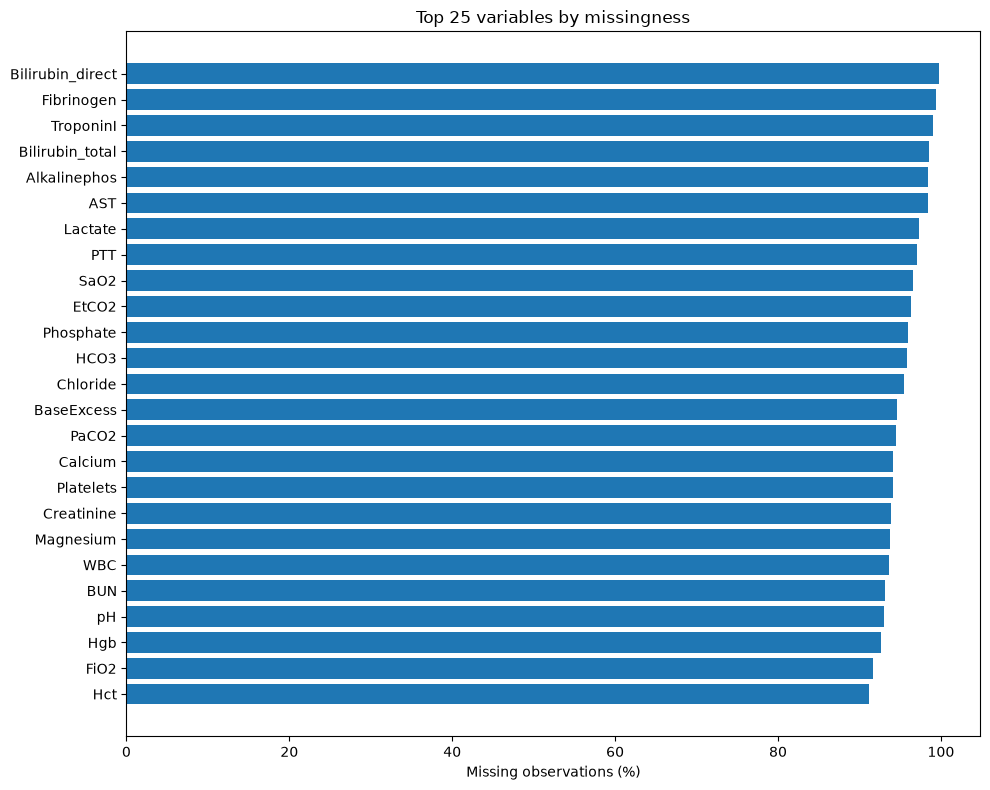

In [6]:
missing_pct = (df.isna().mean()*100).sort_values(ascending=False)
missing_table = pd.DataFrame({"missing_count": df.isna().sum(), "missing_pct": df.isna().mean()*100}).sort_values("missing_pct", ascending=False)
display(missing_table.head(20))
missing_table.to_csv(EDA_DIR / "missingness_by_column.csv")

plot_data = missing_pct.head(25).sort_values()
plt.figure(figsize=(10, 8))
plt.barh(plot_data.index, plot_data.values)
plt.xlabel("Missing observations (%)")
plt.title("Top 25 variables by missingness")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_missingness_top25.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Is measurement availability different on positive-labelled hours?

This is a descriptive comparison, not evidence that missingness causes sepsis or that clinicians deliberately measured more because of sepsis. The label is an early-warning label and measurements may reflect care processes, severity, and timing.

,label_0_missing_pct,label_1_missing_pct,difference_pp_1_minus_0
MAP,12.505396,9.496346,-3.009050
O2Sat,13.110594,10.359650,-2.750944
HR,9.918165,7.941682,-1.976483
DBP,31.372622,29.886087,-1.486536
Resp,15.373084,14.343029,-1.030055
Temp,66.164664,66.055309,-0.109355
SBP,14.565628,15.195587,0.629958


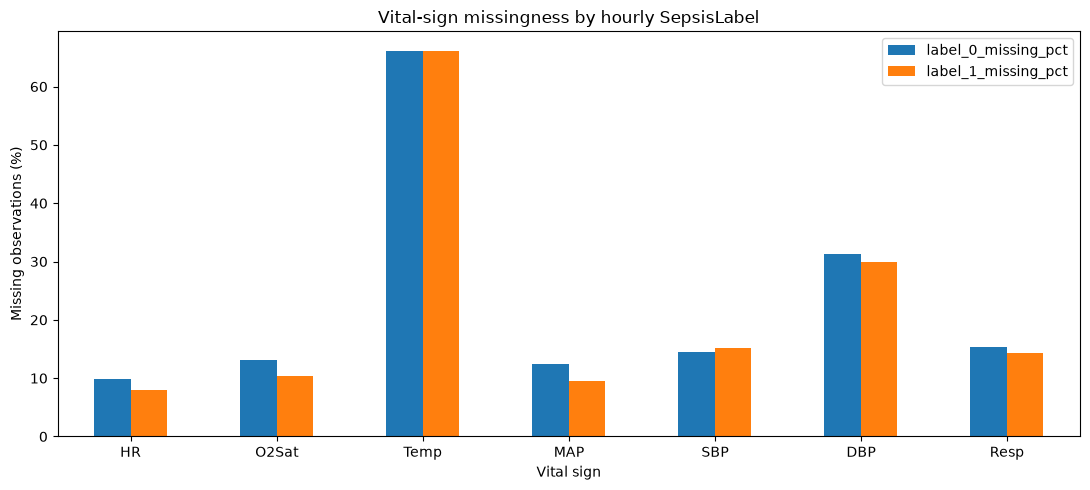

In [7]:
VITALS = [c for c in ["HR", "O2Sat", "Temp", "MAP", "SBP", "DBP", "Resp"] if c in df.columns]
missing_by_label = df.groupby("SepsisLabel")[VITALS].apply(lambda x: x.isna().mean()*100).T
missing_by_label.columns = ["label_0_missing_pct", "label_1_missing_pct"]
missing_by_label["difference_pp_1_minus_0"] = missing_by_label["label_1_missing_pct"] - missing_by_label["label_0_missing_pct"]
display(missing_by_label.sort_values("difference_pp_1_minus_0"))
missing_by_label.to_csv(EDA_DIR / "vital_missingness_by_label.csv")

ax = missing_by_label[["label_0_missing_pct", "label_1_missing_pct"]].plot(kind="bar", figsize=(11,5))
ax.set_ylabel("Missing observations (%)")
ax.set_title("Vital-sign missingness by hourly SepsisLabel")
ax.set_xlabel("Vital sign")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_vital_missingness_by_label.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Distribution analysis for selected vital signs

Use histograms and summary statistics to understand the observed distributions. Extreme values are not automatically errors; investigate them in context.

,count,mean,std,min,25%,50%,75%,max,missing_pct
HR,1398811.0,84.581443,17.325242,20.0,72.0,83.5,95.5,280.0,9.882619
O2Sat,1349474.0,97.193955,2.936924,20.0,96.0,98.0,99.5,100.0,13.061119
Temp,525226.0,36.977228,0.770014,20.9,36.5,37.0,37.5,50.0,66.162697
MAP,1358940.0,82.400100,16.341750,20.0,71.0,80.0,92.0,300.0,12.451279
SBP,1325945.0,123.750465,23.231556,20.0,107.0,121.0,138.0,300.0,14.576958
DBP,1065656.0,63.830556,13.956010,20.0,54.0,62.0,72.0,300.0,31.345887
Resp,1313875.0,18.726498,5.098194,1.0,15.0,18.0,21.5,100.0,15.354559


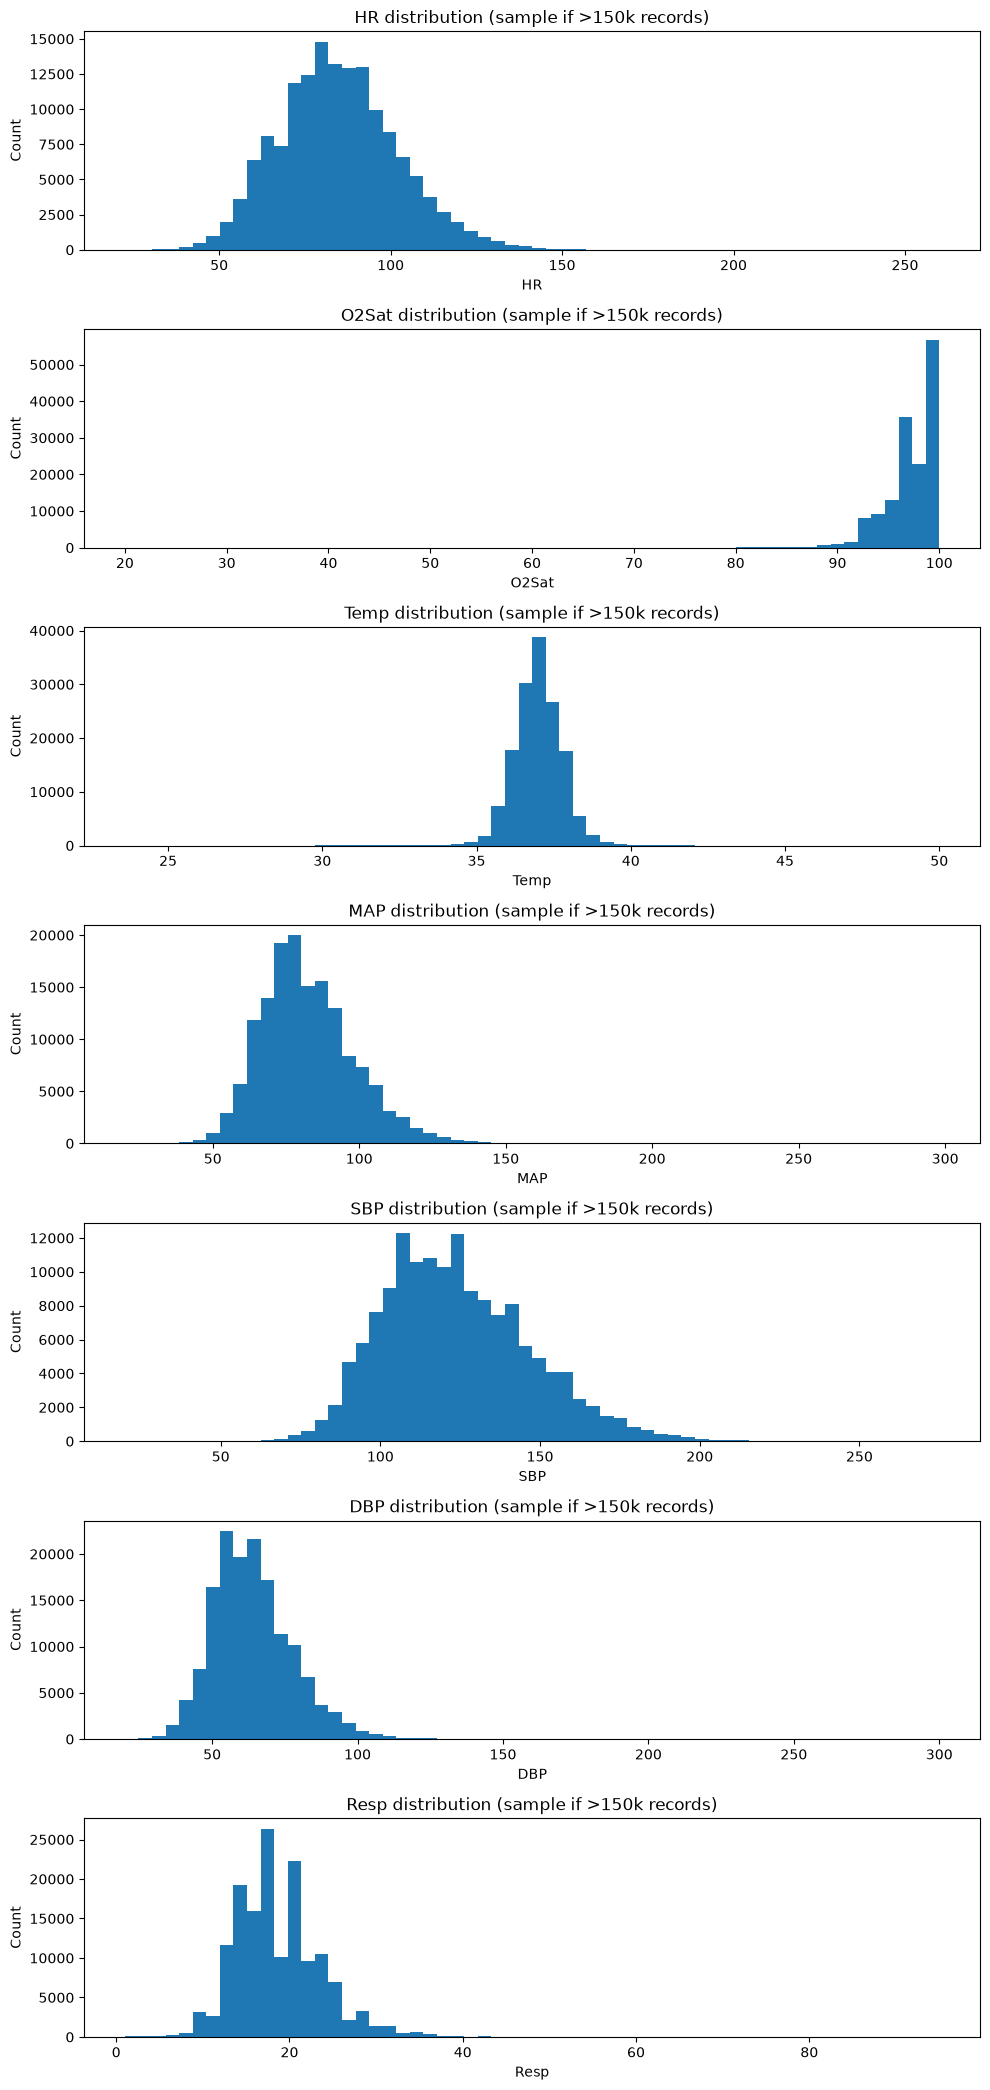

In [8]:
summary_vitals = df[VITALS].describe().T
summary_vitals["missing_pct"] = df[VITALS].isna().mean()*100
display(summary_vitals)
summary_vitals.to_csv(EDA_DIR / "selected_vital_summary.csv")

fig, axes = plt.subplots(len(VITALS), 1, figsize=(10, 3*len(VITALS)))
for ax, col in zip(np.atleast_1d(axes), VITALS):
    vals = df[col].dropna()
    if len(vals) > 150_000:
        vals = vals.sample(150_000, random_state=42)
    ax.hist(vals, bins=60)
    ax.set_title(f"{col} distribution (sample if >150k records)")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_vital_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Statistical outlier screening — flag, do not delete

The IQR rule is used as a statistical screening method. An IQR flag is not proof that a clinical measurement is incorrect. Keep extreme values until they have been investigated with domain knowledge.

In [9]:
outlier_rows = []
for col in VITALS:
    x = df[col].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = int(((x < lower) | (x > upper)).sum())
    outlier_rows.append({"feature": col, "observed_n": len(x), "q1": q1, "q3": q3,
                         "iqr_lower_fence": lower, "iqr_upper_fence": upper,
                         "iqr_flagged_n": n_out, "iqr_flagged_pct_of_observed": 100*n_out/len(x)})
outlier_report = pd.DataFrame(outlier_rows).sort_values("iqr_flagged_pct_of_observed", ascending=False)
display(outlier_report)
outlier_report.to_csv(EDA_DIR / "iqr_outlier_screening_vitals.csv", index=False)

,feature,observed_n,q1,q3,iqr_lower_fence,iqr_upper_fence,iqr_flagged_n,iqr_flagged_pct_of_observed
6,Resp,1313875,15.0,21.5,5.25,31.25,27855,2.120065
1,O2Sat,1349474,96.0,99.5,90.75,104.75,24782,1.836419
3,MAP,1358940,71.0,92.0,39.50,123.50,21894,1.611109
5,DBP,1065656,54.0,72.0,27.00,99.00,16296,1.529199
2,Temp,525226,36.5,37.5,35.00,39.00,6569,1.250700
4,SBP,1325945,107.0,138.0,60.50,184.50,15842,1.194771
0,HR,1398811,72.0,95.5,36.75,130.75,14032,1.003138


## 10. Correlation analysis among vital signs

Correlation measures association, not causation. Use pairwise available observations; mention that missingness can affect the number of records contributing to each pair.

,HR,O2Sat,Temp,MAP,SBP,DBP,Resp
HR,1.000000,-0.063437,0.255232,0.070529,-0.035684,0.125446,0.212933
O2Sat,-0.063437,1.000000,-0.048616,0.019044,0.009537,-0.008266,-0.158658
Temp,0.255232,-0.048616,1.000000,-0.070718,-0.005731,-0.126082,0.122356
MAP,0.070529,0.019044,-0.070718,1.000000,0.780620,0.864831,0.052635
SBP,-0.035684,0.009537,-0.005731,0.780620,1.000000,0.525765,0.049952
DBP,0.125446,-0.008266,-0.126082,0.864831,0.525765,1.000000,0.065660
Resp,0.212933,-0.158658,0.122356,0.052635,0.049952,0.065660,1.000000


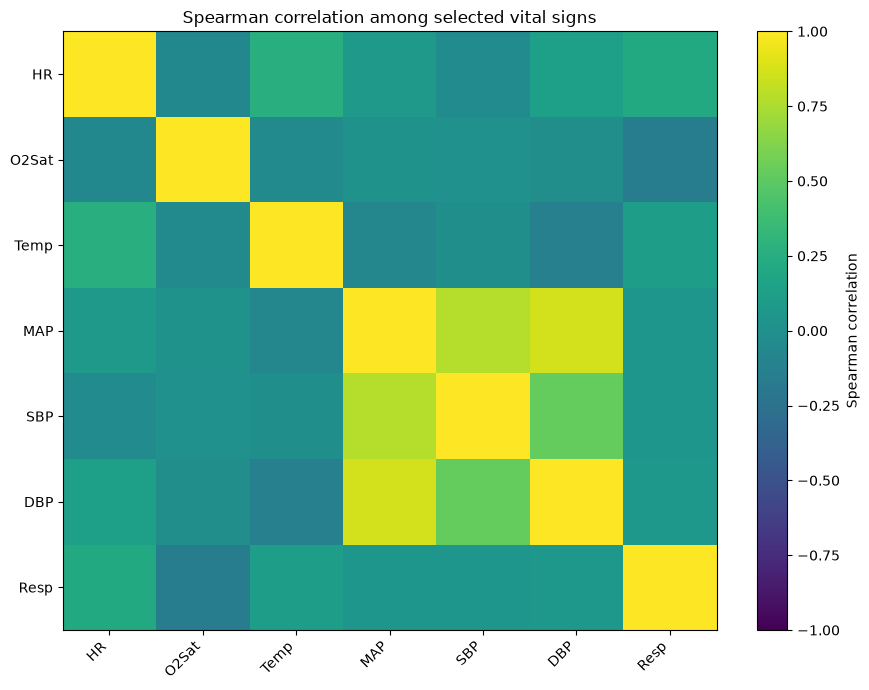

In [10]:
correlations = df[VITALS].corr(method="spearman", min_periods=1000)
display(correlations)

fig, ax = plt.subplots(figsize=(9,7))
image = ax.imshow(correlations.values, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(VITALS)), VITALS, rotation=45, ha="right")
ax.set_yticks(range(len(VITALS)), VITALS)
ax.set_title("Spearman correlation among selected vital signs")
fig.colorbar(image, ax=ax, label="Spearman correlation")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_vital_spearman_correlation.png", dpi=160, bbox_inches="tight")
plt.show()
correlations.to_csv(EDA_DIR / "vital_spearman_correlation.csv")

## 11. Patient observation duration

One patient may contribute many more hourly observations than another. This matters because row-level summaries weight patients with longer ICU stays more heavily.

count    40336.000000
mean        38.482001
std         22.795923
min          8.000000
25%         24.000000
50%         38.000000
75%         47.000000
90%         55.000000
95%         58.000000
max        336.000000
Name: observations, dtype: float64

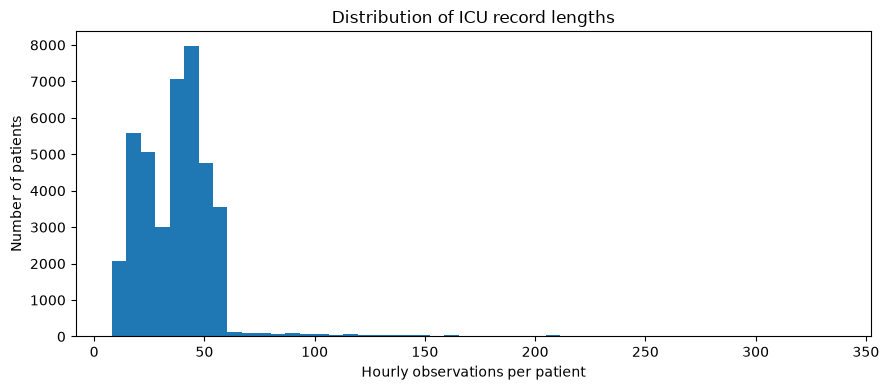

In [11]:
patient_summary = ordered.groupby("Patient_ID").agg(
    observations=("Hour", "size"),
    any_positive_label=("SepsisLabel", "max"),
    positive_hours=("SepsisLabel", "sum"),
    first_positive_hour=("Hour", lambda s: np.nan)
)
first_positive = ordered.loc[ordered["SepsisLabel"].eq(1)].groupby("Patient_ID")["Hour"].min()
patient_summary["first_positive_hour"] = first_positive
patient_summary.to_csv(EDA_DIR / "patient_level_summary.csv")
display(patient_summary["observations"].describe(percentiles=[.25,.5,.75,.9,.95]))

plt.figure(figsize=(9,4))
plt.hist(patient_summary["observations"], bins=50)
plt.xlabel("Hourly observations per patient")
plt.ylabel("Number of patients")
plt.title("Distribution of ICU record lengths")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_patient_record_lengths.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Cohort trajectory around the first positive challenge label

For patients with at least one positive label, define relative hour 0 as the **first positive `SepsisLabel` hour** (the beginning of the challenge warning window), not the clinical sepsis onset. Summarize the previous 12 hours through 6 hours after that label. Different patients contribute at different hours; always inspect the count alongside the median.

,observed_n,median,q25,q75,feature,relative_hour
0,1782,88.0,76.00,100.000,HR,-12
1,1831,88.0,76.00,102.000,HR,-11
2,1868,88.0,75.75,101.000,HR,-10
3,1913,88.0,76.00,101.000,HR,-9
4,1924,88.0,76.00,102.000,HR,-8
5,1961,88.0,76.00,101.000,HR,-7
6,2025,88.0,76.00,101.000,HR,-6
7,2071,88.0,76.00,101.000,HR,-5
8,2135,88.0,76.00,101.000,HR,-4
9,2183,88.0,76.00,101.000,HR,-3


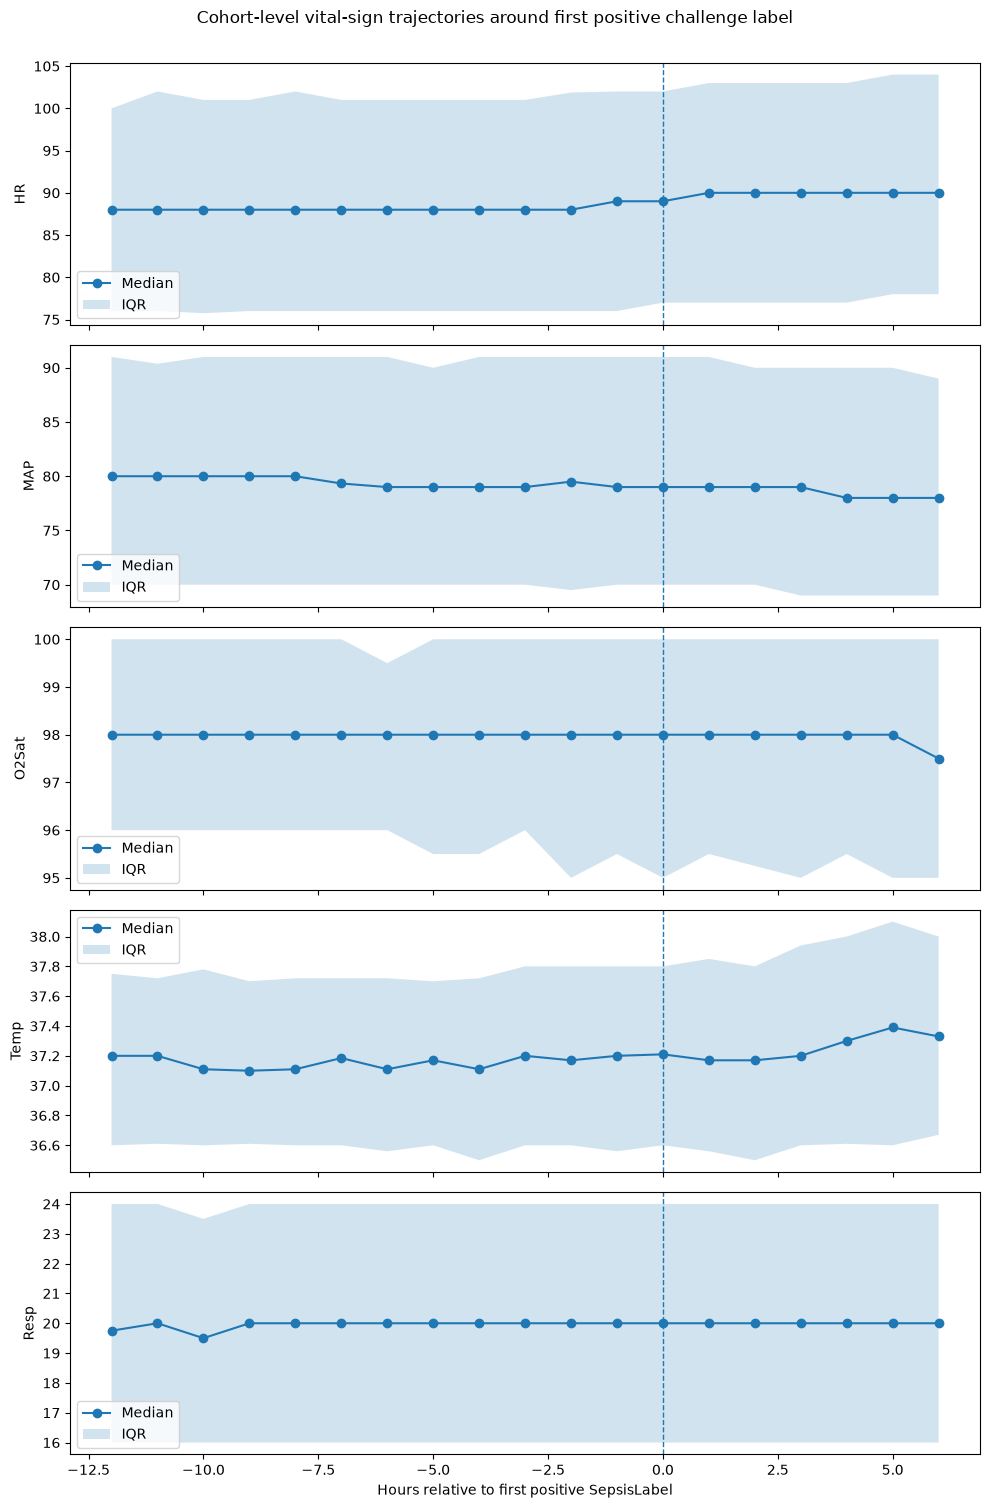

In [12]:
pos_ids = set(first_positive.index)
septic = ordered.loc[ordered["Patient_ID"].isin(pos_ids), ["Patient_ID", "Hour", "SepsisLabel"] + VITALS].copy()
septic["first_positive_hour"] = septic["Patient_ID"].map(first_positive)
septic["relative_hour"] = septic["Hour"] - septic["first_positive_hour"]
window = septic.loc[septic["relative_hour"].between(-12, 6)].copy()

trajectory_parts = []
for col in [c for c in ["HR", "MAP", "O2Sat", "Temp", "Resp"] if c in window.columns]:
    stats = window.groupby("relative_hour")[col].agg(
        observed_n="count", median="median", q25=lambda s:s.quantile(.25), q75=lambda s:s.quantile(.75)
    )
    stats["feature"] = col
    stats["relative_hour"] = stats.index
    trajectory_parts.append(stats.reset_index(drop=True))
trajectory = pd.concat(trajectory_parts, ignore_index=True)
trajectory.to_csv(EDA_DIR / "cohort_trajectory_relative_to_first_positive_label.csv", index=False)
display(trajectory.head(20))

fig, axes = plt.subplots(5, 1, figsize=(10, 15), sharex=True)
for ax, col in zip(axes, ["HR", "MAP", "O2Sat", "Temp", "Resp"]):
    sub = trajectory.loc[trajectory["feature"].eq(col)]
    ax.plot(sub["relative_hour"], sub["median"], marker="o", label="Median")
    ax.fill_between(sub["relative_hour"], sub["q25"], sub["q75"], alpha=.2, label="IQR")
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_ylabel(col)
    ax.legend(loc="best")
axes[-1].set_xlabel("Hours relative to first positive SepsisLabel")
fig.suptitle("Cohort-level vital-sign trajectories around first positive challenge label", y=1.002)
plt.tight_layout()
plt.savefig(FIG_DIR / "07_cohort_trajectories.png", dpi=160, bbox_inches="tight")
plt.show()

## 13. Measurement-availability fingerprint around the warning window

This chart asks whether the percentage of missing measurements changes around the first positive challenge label. It is a data-collection pattern analysis, not evidence of clinical suspicion or causation.

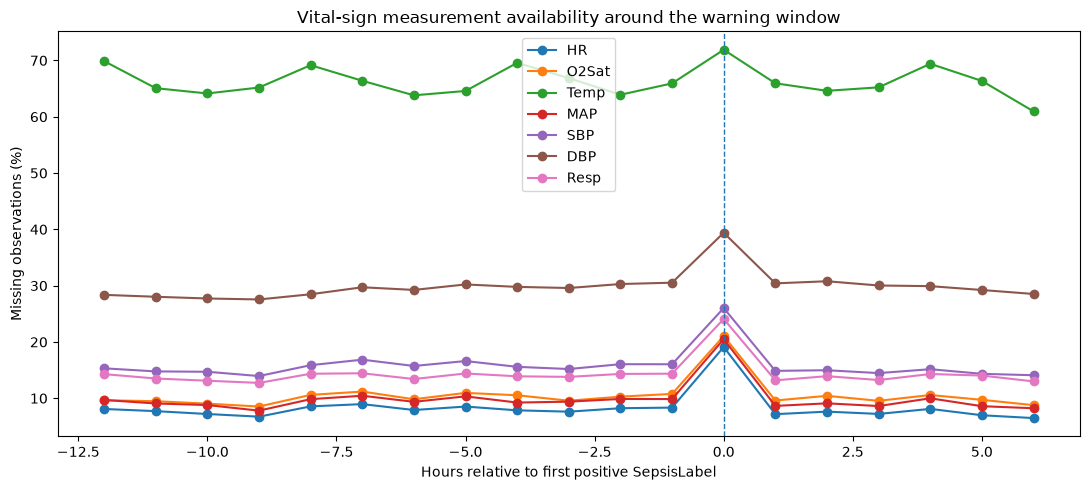

In [13]:
availability = window.groupby("relative_hour")[VITALS].apply(lambda x: x.isna().mean()*100)
availability.to_csv(EDA_DIR / "missingness_by_relative_hour.csv")

ax = availability.plot(figsize=(11,5), marker="o")
ax.set_xlabel("Hours relative to first positive SepsisLabel")
ax.set_ylabel("Missing observations (%)")
ax.set_title("Vital-sign measurement availability around the warning window")
ax.axvline(0, linestyle="--", linewidth=1)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_missingness_fingerprint.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Evidence-backed EDA findings

This cell prints key numbers directly from the file. Use the generated tables and charts to write the final interpretation. Do not claim causal relationships from descriptive analysis.

In [14]:
print("EDA FINDINGS — GENERATED FROM THIS CSV")
print(f"Rows: {len(df):,}; columns in analysis copy: {df.shape[1]}; unique patients: {df.Patient_ID.nunique():,}")
print(f"Positive hourly labels: {int(df.SepsisLabel.sum()):,} ({df.SepsisLabel.mean()*100:.3f}% of rows)")
print(f"Patients with at least one positive label: {positive_patients:,} ({positive_patients/df.Patient_ID.nunique()*100:.2f}% of patients)")
print(f"Median observations per patient: {patient_lengths.median():.0f}; IQR: {patient_lengths.quantile(.25):.0f}–{patient_lengths.quantile(.75):.0f}; range: {patient_lengths.min()}–{patient_lengths.max()}")
print("Most-missing variables:")
print(missing_table.head(8).round(2).to_string())
print("Selected vital missingness (%):")
print((df[VITALS].isna().mean()*100).round(2).to_string())
print("Structural checks:", {"exact_duplicates": exact_duplicates, "duplicate_patient_hour": duplicate_patient_hours, "nonconsecutive_hour_gaps": nonconsecutive_gaps})

findings = {
    "rows": int(len(df)), "columns_after_index_check": int(df.shape[1]),
    "unique_patients": int(df.Patient_ID.nunique()),
    "positive_hourly_labels": int(df.SepsisLabel.sum()),
    "positive_hourly_pct": float(df.SepsisLabel.mean()*100),
    "positive_patients": int(positive_patients),
    "positive_patient_pct": float(positive_patients/df.Patient_ID.nunique()*100),
    "median_rows_per_patient": float(patient_lengths.median()),
    "mean_rows_per_patient": float(patient_lengths.mean()),
    "exact_duplicates": exact_duplicates,
    "duplicate_patient_hour": duplicate_patient_hours,
    "nonconsecutive_hour_gaps": nonconsecutive_gaps,
    "top_missing_features": missing_table.head(10).to_dict(orient="index")
}
(EDA_DIR / "eda_key_findings.json").write_text(json.dumps(findings, indent=2, default=float))
print("Saved EDA tables and figures to:", EDA_DIR)

EDA FINDINGS — GENERATED FROM THIS CSV
Rows: 1,552,210; columns in analysis copy: 43; unique patients: 40,336
Positive hourly labels: 27,916 (1.798% of rows)
Patients with at least one positive label: 2,932 (7.27% of patients)
Median observations per patient: 38; IQR: 24–47; range: 8–336
Most-missing variables:
                  missing_count  missing_pct
Bilirubin_direct        1549220        99.81
Fibrinogen              1541968        99.34
TroponinI               1537429        99.05
Bilirubin_total         1529069        98.51
Alkalinephos            1527269        98.39
AST                     1527027        98.38
Lactate                 1510764        97.33
PTT                     1506511        97.06
Selected vital missingness (%):
HR        9.88
O2Sat    13.06
Temp     66.16
MAP      12.45
SBP      14.58
DBP      31.35
Resp     15.35
Structural checks: {'exact_duplicates': 0, 'duplicate_patient_hour': 0, 'nonconsecutive_hour_gaps': 0}
Saved EDA tables and figures to: /Users/mo

## 15. Person 1 handoff

Send Person 2:
- `schema_and_missingness.csv`
- `missingness_by_column.csv`
- `iqr_outlier_screening_vitals.csv`
- `dataset_integrity_summary.csv`
- EDA charts and your written interpretation.

**Decisions to discuss as a team:** which values are valid extremes versus errors, whether any rows need correction, and how to preserve missingness. Do not make irreversible deletion or imputation choices from an IQR chart alone.